# Phase 2: Exploratory Data Analysis & Preprocessing Pipeline
## Peripheral Blood Smear White Blood Cell Classification Using Deep Learning
**Specialisation:** AI/ML Capstone Project | **Domain:** Healthcare AI & Computer Vision  
**Target:** 5-Class WBC Classification (Neutrophil, Lymphocyte, Monocyte, Eosinophil, Basophil)

---

### Notebook Objectives:
1. **Dataset Audit:** Inspect file structures, formats, sample counts, and verify integrity across `Train`, `Test-A`, and `Test-B`.
2. **Imbalance Analysis:** Compute raw frequencies and class percentages to quantify natural biological imbalance.
3. **Morphological Inspection:** Visualize high-resolution representative samples from all 5 WBC subtypes.
4. **Color & Geometry Analysis:** Analyze pixel intensities (staining effects) and aspect ratio distributions.
5. **Leak-Free Splitting & Weights:** Construct stratified 80/20 train/val splits and compute class weights for training.
6. **DataLoaders:** Test PyTorch dataset and data loaders with augmentation transforms.

In [1]:
import os
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch

# Add src/ to system path
sys.path.append(os.path.abspath('..'))
from src.dataset import (
    CLASSES, CLASS_TO_IDX, IDX_TO_CLASS,
    load_dataset_dataframe,
    create_stratified_train_val_split,
    compute_class_weights,
    get_dataloaders,
    denormalize_image
)

# Plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120
print(f"PyTorch Version: {torch.__version__}")
print(f"Target Classes ({len(CLASSES)}): {CLASSES}")

PyTorch Version: 2.14.1+cpu
Target Classes (5): ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']


---
## 1. Dataset Loading and Split Verification
We scan the dataset directory (`WBC archive/`) containing:
- **`Train/`**: 5-class training collection.
- **`Test-A/`**: Held-out benchmark test set containing all 5 classes.
- **`Test-B/`**: External generalization test set (Lymphocytes & Neutrophils only).

In [2]:
base_dir = os.path.join("..", "WBC archive")
df_train, df_test_a, df_test_b = load_dataset_dataframe(base_dir=base_dir)

print(f"Train split images:   {len(df_train):,}")
print(f"Test-A split images:  {len(df_test_a):,}")
print(f"Test-B split images:  {len(df_test_b):,}")
print(f"Total dataset images: {len(df_train) + len(df_test_a) + len(df_test_b):,}")

Train split images:   10,175
Test-A split images:  4,339
Test-B split images:  2,119
Total dataset images: 16,633


---
## 2. Class Distribution & Imbalance Assessment
We examine the distribution across all 5 classes to quantify the majority-minority class skew.

Split,Test-A,Test-B,Train,Total,Train %
Class,,,,,
Basophil,89,0,212,301,2.08
Eosinophil,322,0,744,1066,7.31
Lymphocyte,1034,148,2427,3609,23.85
Monocyte,234,0,561,795,5.51
Neutrophil,2660,1971,6231,10862,61.24


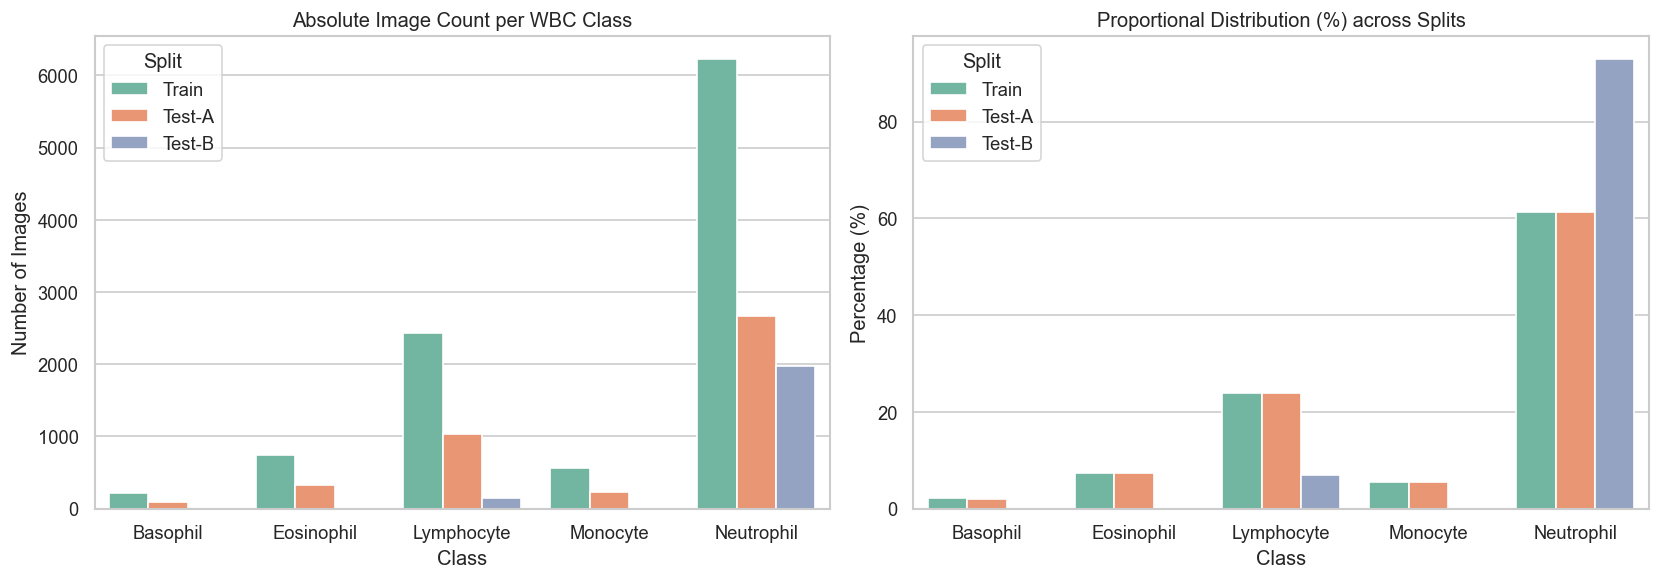

In [3]:
# Summary table
records = []
for split_name, df in [('Train', df_train), ('Test-A', df_test_a), ('Test-B', df_test_b)]:
    counts = df['class_name'].value_counts()
    for c in CLASSES:
        cnt = counts.get(c, 0)
        pct = (cnt / len(df) * 100) if len(df) > 0 else 0
        records.append({'Split': split_name, 'Class': c, 'Count': cnt, 'Percentage': pct})

df_summary = pd.DataFrame(records)
pivot_counts = df_summary.pivot(index='Class', columns='Split', values='Count').fillna(0).astype(int)
pivot_counts['Total'] = pivot_counts.sum(axis=1)
pivot_counts['Train %'] = (pivot_counts['Train'] / len(df_train) * 100).round(2)
display(pivot_counts)

# Visualizing distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_summary, x='Class', y='Count', hue='Split', palette='Set2', ax=ax1)
ax1.set_title('Absolute Image Count per WBC Class')
ax1.set_ylabel('Number of Images')

sns.barplot(data=df_summary, x='Class', y='Percentage', hue='Split', palette='Set2', ax=ax2)
ax2.set_title('Proportional Distribution (%) across Splits')
ax2.set_ylabel('Percentage (%)')

plt.tight_layout()
plt.show()

---
## 3. Representative Microscopic Morphology
Visualizing representative cells from each of the 5 WBC classes to verify key cellular hallmarks:
- **Basophil**: Intense purple-black coarse granules obscuring the nucleus.
- **Eosinophil**: Bilobed nucleus with bright orange-pink granules.
- **Lymphocyte**: Spherical, dense dark nucleus with high nuclear-to-cytoplasmic ratio.
- **Monocyte**: Kidney-shaped / folded nucleus with abundant grayish-blue cytoplasm.
- **Neutrophil**: 3-5 segmented lobes connected by chromatin filaments.

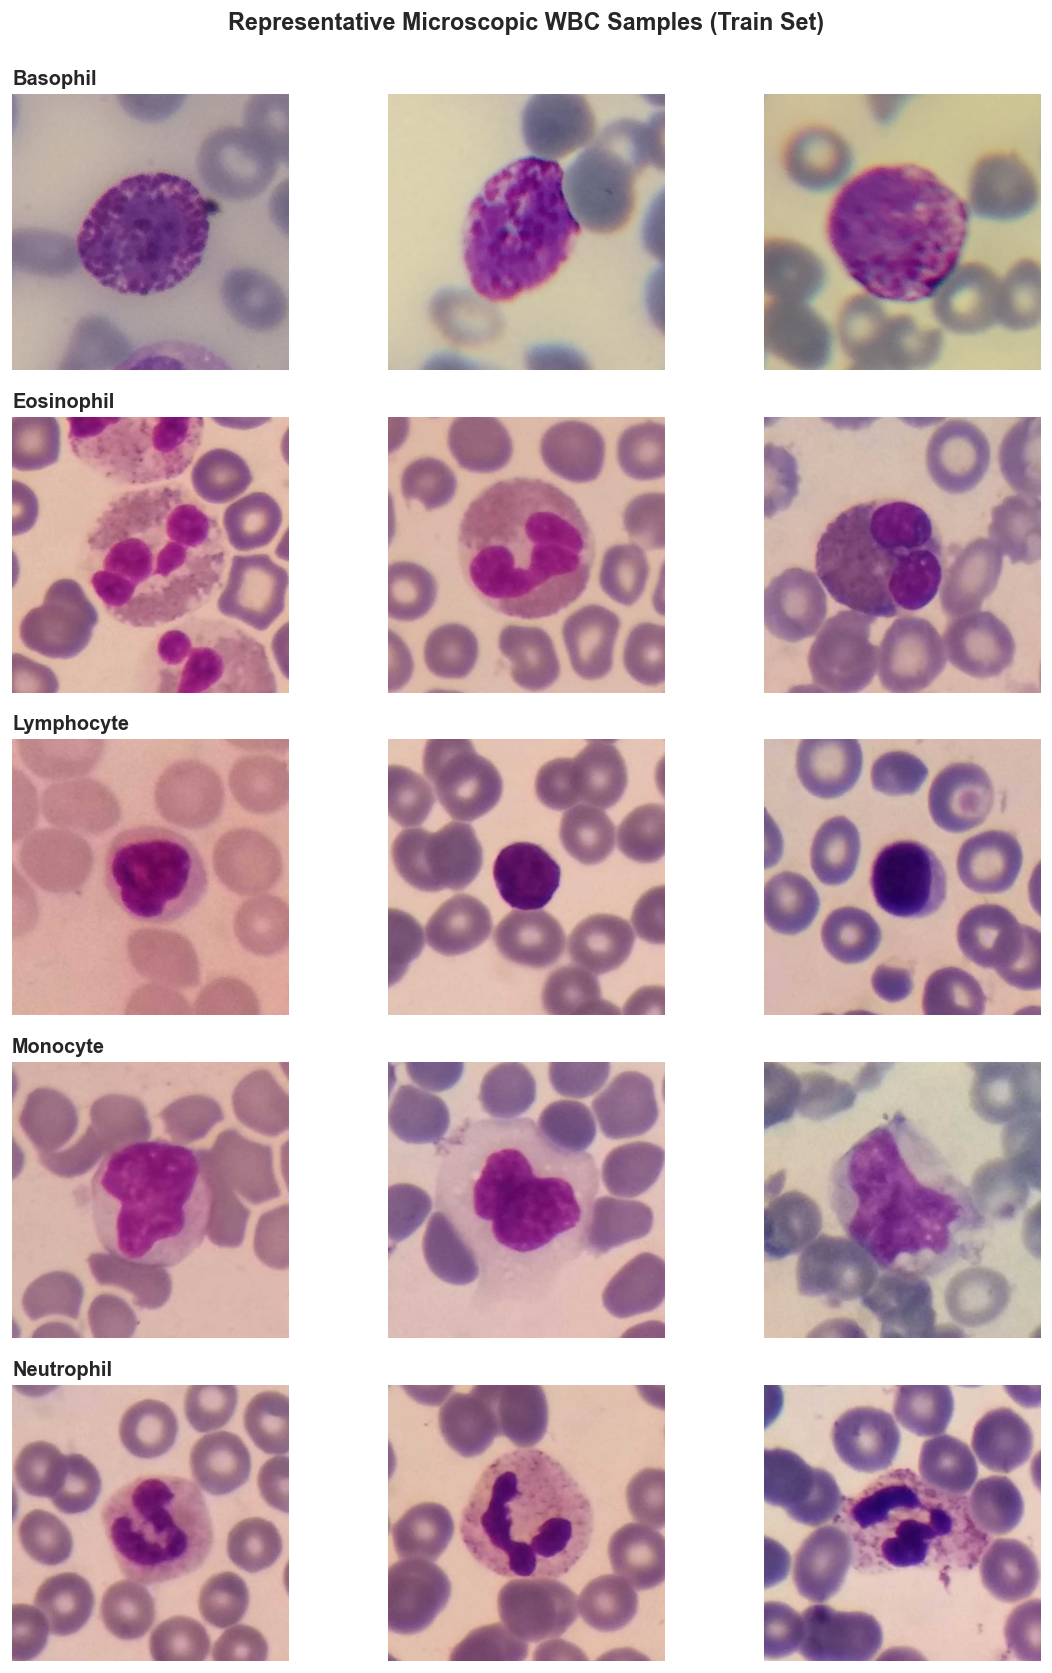

In [4]:
samples_per_class = 3
fig, axes = plt.subplots(len(CLASSES), samples_per_class, figsize=(10, 14))

for row_idx, cls in enumerate(CLASSES):
    subset = df_train[df_train['class_name'] == cls]
    samples = subset.sample(n=samples_per_class, random_state=42)
    for col_idx, (_, row) in enumerate(samples.iterrows()):
        ax = axes[row_idx, col_idx]
        img = Image.open(row['filepath'])
        ax.imshow(img)
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(f"{cls}", loc='left', fontsize=12, fontweight='bold')

plt.suptitle("Representative Microscopic WBC Samples (Train Set)", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

---
## 4. Leakage-Free Stratified Train / Validation Split
To evaluate our models during training without touching the held-out `Test-A` set, we perform a **stratified 80/20 split** on `Train`.

In [5]:
df_tr, df_val = create_stratified_train_val_split(df_train, val_ratio=0.20, random_state=42)

print(f"Training subset:   {len(df_tr):,} images")
print(f"Validation subset: {len(df_val):,} images")
print(f"Held-out Test-A:   {len(df_test_a):,} images")

# Verify stratification consistency
tr_dist = df_tr['class_name'].value_counts(normalize=True).mul(100).round(2)
val_dist = df_val['class_name'].value_counts(normalize=True).mul(100).round(2)
df_strat_check = pd.DataFrame({'Train Subset (%)': tr_dist, 'Val Subset (%)': val_dist})
display(df_strat_check)

# Compute inverse frequency class weights
weights = compute_class_weights(df_tr)
print("\nInverse Class Weights for Balanced Loss:")
for c, w in zip(CLASSES, weights):
    print(f"  {c:12s}: {w.item():.4f}")

Training subset:   8,140 images
Validation subset: 2,035 images
Held-out Test-A:   4,339 images


,Train Subset (%),Val Subset (%)
class_name,,
Neutrophil,61.24,61.23
Lymphocyte,23.85,23.88
Eosinophil,7.31,7.32
Monocyte,5.52,5.50
Basophil,2.09,2.06



Inverse Class Weights for Balanced Loss:
  Basophil    : 2.7995
  Eosinophil  : 0.7999
  Lymphocyte  : 0.2452
  Monocyte    : 1.0600
  Neutrophil  : 0.0955


---
## 5. PyTorch DataLoader Verification & Augmentation Inspection
We verify that batches load correctly and inspect augmented images.

Batch image tensor shape: torch.Size([16, 3, 224, 224])
Batch label tensor shape: torch.Size([16])


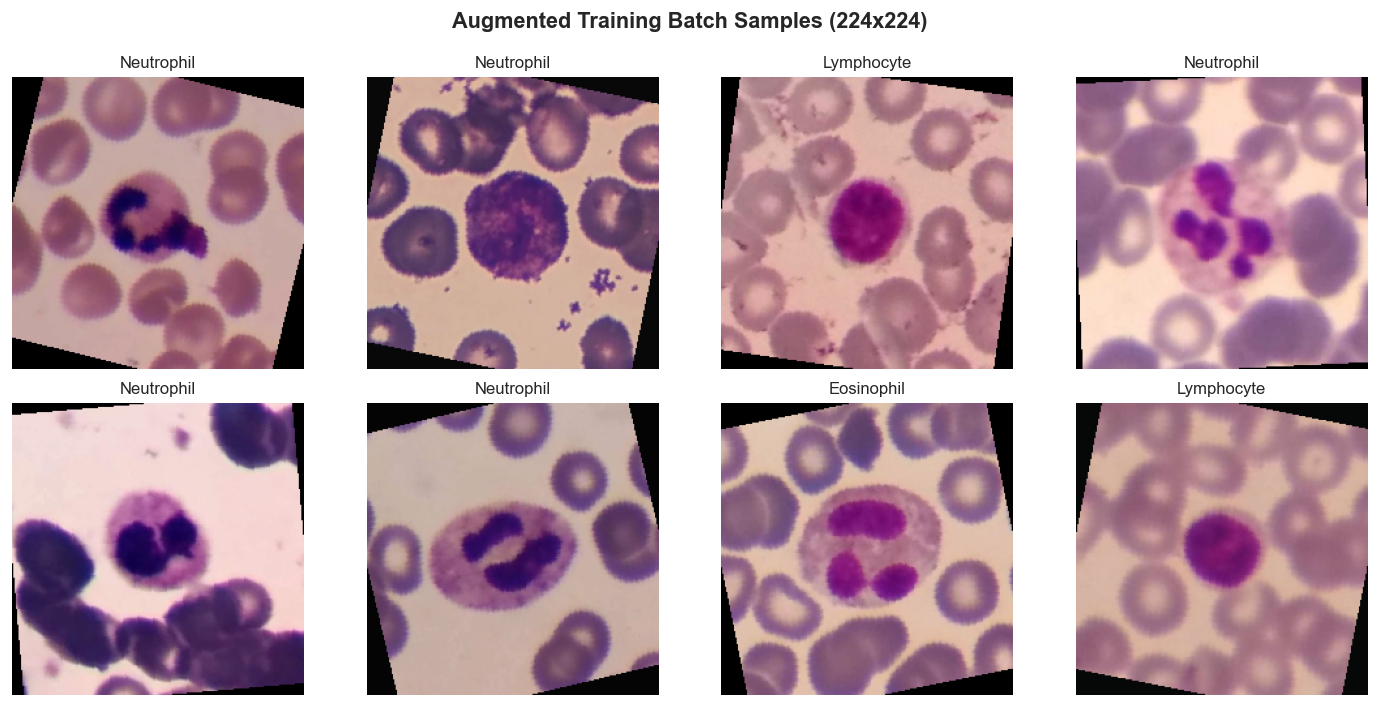

In [6]:
dataloaders = get_dataloaders(
    df_train=df_tr,
    df_val=df_val,
    df_test=df_test_a,
    batch_size=16,
    num_workers=0,
    image_size=(224, 224)
)

train_batch, label_batch = next(iter(dataloaders['train']))
print(f"Batch image tensor shape: {train_batch.shape}")
print(f"Batch label tensor shape: {label_batch.shape}")

# Visualize a mini-batch of augmented images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()
for i in range(8):
    img_np = denormalize_image(train_batch[i])
    axes[i].imshow(img_np)
    axes[i].set_title(f"{IDX_TO_CLASS[label_batch[i].item()]}", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Augmented Training Batch Samples (224x224)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 6. Key Takeaways & Transition to Phase 3
1. **Severe Imbalance Handled:** Neutrophils (~61%) vs Basophils (~2.1%). Class weights computed and ready for Cross-Entropy loss.
2. **Leakage Safeguards Verified:** Stratified train/val split is isolated from held-out `Test-A`. Augmentations applied only to training data.
3. **Pipeline Validated:** 224x224 tensors with ImageNet normalization are compatible with baseline CNN and MobileNetV2.
4. **Next Phase:** Proceed with Phase 3: Implementing and training the Custom Baseline CNN.